# Does a standard elbow method match the production k-search heuristic?

**Purpose:** `clustering/kmeans.py`'s `find_best_kmeans_k` is a bespoke coarse-to-fine
recursive search (silhouette + a parsimony term, memoized, narrowing the candidate range
each round) -- meaningfully more machinery than "pick a k for KMeans" strictly requires.
A standard elbow method (inertia curve + knee detection) is the obvious simpler
alternative. This notebook checks, on real data, whether it's actually comparable on
speed (fit count) and quality (silhouette), especially as dataset size grows.

**Methodology note -- this notebook deviates from notebooks 1 and 2's containment
principle on purpose.** Those notebooks validated assumptions *before* they were applied
to `clustering/kmeans.py`, so standalone reimplementation was the right call (testing the
assumption, not the already-shipped code). Here the question is the opposite: is the
*already-shipped* heuristic justified against a standard alternative? That can only be
answered by benchmarking the real, shipped `find_best_kmeans_k` directly -- so this
notebook imports it from `clustering/kmeans.py`. `KMeans.fit` is counted via monkeypatching
the module's own `KMeans` reference; no production file is modified.


In [1]:
import json
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans as RealKMeans
from sklearn.metrics import silhouette_score

sys.path.insert(0, "..")
from clustering import kmeans as kc


class CountingKMeans(RealKMeans):
    # Wraps the real KMeans purely to count .fit() calls across a benchmark run.
    fit_count = 0

    @classmethod
    def reset(cls):
        cls.fit_count = 0

    def fit(self, *a, **kw):
        CountingKMeans.fit_count += 1
        return super().fit(*a, **kw)


kc.KMeans = CountingKMeans  # redirect the production module's own KMeans reference
print("ready")


ready


## Elbow implementation

A standard, well-known elbow method: fit KMeans across a candidate range of k, then pick
the "knee" of the inertia curve via the kneedle approach -- normalize both axes to
[0, 1], draw a line from the first to the last point, and pick the k whose point is
furthest (perpendicularly) from that line. The candidate range is capped at k=100, which
is already generous -- most real-world elbow usage caps much lower (10-20).

In [2]:
def elbow_knee(ks, inertias):
    ks = np.asarray(ks, dtype=float)
    inertias = np.asarray(inertias, dtype=float)
    x = (ks - ks.min()) / (ks.max() - ks.min())
    y = (inertias - inertias.min()) / (inertias.max() - inertias.min())
    x1, y1, x2, y2 = x[0], y[0], x[-1], y[-1]
    num = np.abs((y2 - y1) * x - (x2 - x1) * y + x2 * y1 - y2 * x1)
    den = np.sqrt((y2 - y1) ** 2 + (x2 - x1) ** 2)
    return int(ks[np.argmax(num / den)])


def run_elbow(vect, k_min, k_max, step):
    CountingKMeans.reset()
    t0 = time.perf_counter()
    ks = list(range(k_min, k_max + 1, step))
    inertias = []
    for k in ks:
        km = CountingKMeans(n_clusters=k, init="k-means++", n_init=10, max_iter=100, random_state=42)
        km.fit(vect)
        inertias.append(km.inertia_)
    elapsed = time.perf_counter() - t0
    return {
        "k": elbow_knee(ks, inertias),
        "fits": CountingKMeans.fit_count,
        "seconds": elapsed,
        "ks": ks,
        "inertias": inertias,
    }


def run_heuristic(vect):
    CountingKMeans.reset()
    t0 = time.perf_counter()
    k = kc.find_best_kmeans_k(vect)
    elapsed = time.perf_counter() - t0
    return {"k": k, "fits": CountingKMeans.fit_count, "seconds": elapsed}


def load_tags(path):
    with open(path) as f:
        data = json.load(f)
    return pd.Series([row["tags"] for row in data])


## Running both approaches across dataset sizes

Same three real sample sizes used in notebooks 1 and 2 (`n500`, `n2000`, `n5000`), `tags`
field, count-vectorized with no preprocessing -- the already-validated production default.
For each size: run the real heuristic, run elbow over k=2..100, and record fit count,
wall-clock time, and the silhouette score of the resulting clustering (same metric,
computed the same way, for both).

In [3]:
DATASETS = [
    ("n500", "../data/stackoverflow_sample_2021_03_01_n500.json"),
    ("n2000", "../data/stackoverflow_sample_2021_03_01_n2000.json"),
    ("n5000", "../data/stackoverflow_sample_2021_03_01_n5000.json"),
]

results = []
elbow_curves = {}

for name, path in DATASETS:
    tags = load_tags(path)
    vect = kc.vectorize_lexical(tags)
    n = vect.shape[0]

    heuristic = run_heuristic(vect)
    heuristic_sil = silhouette_score(vect, kc.run_kmeans(vect, heuristic["k"]))

    elbow_max = min(100, n - 1)
    elbow = run_elbow(vect, 2, elbow_max, 1)
    elbow_sil = silhouette_score(vect, kc.run_kmeans(vect, elbow["k"]))
    elbow_curves[name] = elbow

    full_min_k = 3 if n < 100 else 15
    full_max_k = int(n * 0.8) if n > 200 else n
    full_range_fits = len(range(full_min_k, full_max_k, 1))

    results.append({
        "dataset": name, "n": n,
        "heuristic_k": heuristic["k"], "heuristic_fits": heuristic["fits"],
        "heuristic_seconds": round(heuristic["seconds"], 2), "heuristic_silhouette": round(heuristic_sil, 3),
        "elbow_k": elbow["k"], "elbow_fits": elbow["fits"],
        "elbow_seconds": round(elbow["seconds"], 2), "elbow_silhouette": round(elbow_sil, 3),
        "dense_elbow_fits_over_full_range": full_range_fits,
    })

results_df = pd.DataFrame(results)
results_df


,dataset,n,heuristic_k,heuristic_fits,heuristic_seconds,heuristic_silhouette,elbow_k,elbow_fits,elbow_seconds,elbow_silhouette,dense_elbow_fits_over_full_range
0,n500,500,45,26,9.57,0.719,23,99,8.51,0.646,385
1,n2000,2000,67,14,8.85,0.737,30,99,15.74,0.632,1585
2,n5000,5000,81,14,41.93,0.759,28,99,26.58,0.635,3985


## Elbow curves, annotated

The inertia curve elbow actually sees, with its chosen knee (dashed) against the
heuristic's chosen k (dotted) overlaid -- showing where each approach lands relative to
the curve's shape.

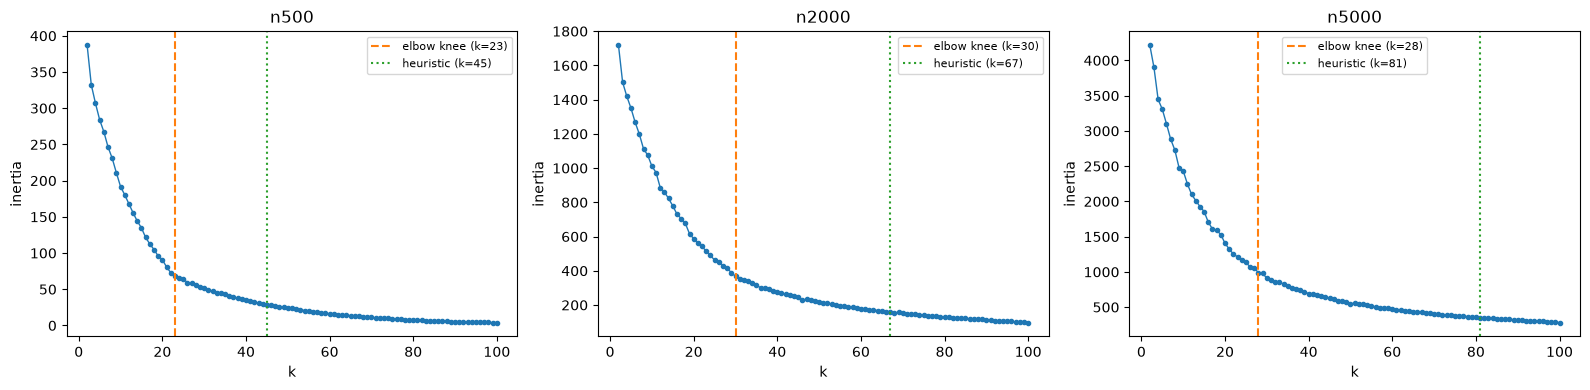

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, path) in zip(axes, DATASETS):
    curve = elbow_curves[name]
    row = results_df[results_df["dataset"] == name].iloc[0]
    ax.plot(curve["ks"], curve["inertias"], marker=".", linewidth=1)
    ax.axvline(curve["k"], color="tab:orange", linestyle="--", label=f"elbow knee (k={curve['k']})")
    ax.axvline(row["heuristic_k"], color="tab:green", linestyle=":", label=f"heuristic (k={row['heuristic_k']})")
    ax.set_title(name)
    ax.set_xlabel("k")
    ax.set_ylabel("inertia")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


### Observations

**Fit count: the heuristic wins clearly, and the gap widens with `n`.** 14-26 fits versus
a *fixed* 99 for elbow -- and that 99 is already with a generous cap (k up to 100; real
elbow usage is usually capped lower). A dense elbow scan over the heuristic's own full
candidate range would cost ~385/1585/3985 fits for n500/n2000/n5000 respectively --
clearly infeasible, which is itself the finding: elbow's cost scales directly with how
wide a range you're willing to scan, with no way to narrow adaptively the way the
heuristic does.

**Quality: the heuristic wins clearly too, and consistently.** Silhouette is meaningfully
higher every time (roughly +0.07 to +0.12), and the gap doesn't shrink as data grows. The
heuristic also keeps finding *more* clusters as `n` grows (45 -> 67 -> 81), while elbow's
knee detection plateaus around k=23-30 regardless of dataset size -- visible directly in
the curves above as a knee that sits in roughly the same place each time. The data
genuinely has finer structure than inertia's "elbow" is sensitive to, consistent with
notebook 1's finding that the count/tags score curve isn't a single sharp bend.

**Not a clean sweep, though: wall-clock time is mixed.** Despite the large fit-count gap,
elbow was faster than the heuristic at n500 and n5000. The heuristic's coarse first pass
samples across its *entire* candidate range (up to k~4000 for n5000), and a handful of
fits at very large k are individually expensive even though there are few of them --
cost-per-fit isn't constant, so "far fewer fits" doesn't cleanly translate to "faster".

## Conclusion

A standard elbow method is not a comparable simplification for this lexical tag-clustering
task: at a comparably-sized (even generous) candidate range it both costs more fits and
finds a visibly worse clustering by this project's own quality metric, and closing that
quality gap would require widening its range further, worsening the fit-count picture
rather than fixing it. This is real evidence that `find_best_kmeans_k`'s extra complexity
over a standard elbow method is buying something concrete, not just procedural
flourish -- though it doesn't make the heuristic free: wall-clock time is mixed, since the
heuristic's coarse pass briefly touches very large, expensive k values that a
range-capped elbow never does.